# Limit Order Book Mid-Price Prediction: walkthrough

This notebook walks through the pipeline step by step. The same steps run end to end in `src/run_pipeline.py`.

**Data:** a simulated NASDAQ trading day in the LOBSTER file format (400,000 events, 10 levels), made by `src/simulate_lobster.py`. The real LOBSTER sample files could not be downloaded from the build environment. Point `DATA_DIR` at a folder of real LOBSTER csvs to run the same notebook on real data.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lob_io import load_lobster
from features import build_features, ABSOLUTE_PRICE_FEATURES
from labels import smoothed_future_return, make_labels, time_split, choose_alpha, CLASS_NAMES
from model import train_lgbm, macro_f1, random_baseline_f1, gain_importance, adversarial_auc
from backtest import run_backtest
DATA_DIR = Path('..') / 'data' / 'simulated'
pd.set_option('display.width', 160)

## 1. Load the order book
Each row is one message (submit, cancel, execution) plus the top 10 levels of the book right after it.

In [2]:
df = load_lobster(DATA_DIR)
print(len(df), 'events')
print(df['type'].value_counts(normalize=True).rename({1:'submit',2:'partial cancel',3:'delete',4:'visible exec',5:'hidden exec'}).round(3))
df[['time','type','size','price','direction','ask_p1','ask_s1','bid_p1','bid_s1']].head()

400000 events
type
submit            0.465
delete            0.402
visible exec      0.087
partial cancel    0.035
hidden exec       0.011
Name: proportion, dtype: float64


,time,type,size,price,direction,ask_p1,ask_s1,bid_p1,bid_s1
0,34200.047875,3,100,585.29,-1,585.05,700,584.95,583
1,34200.054462,3,500,585.30,-1,585.05,700,584.95,583
2,34200.082174,1,300,584.24,1,585.05,700,584.95,583
3,34200.132288,1,64,584.64,1,585.05,700,584.95,583
4,34200.138259,1,89,585.19,-1,585.05,700,584.95,583


spread ($): median 0.120, mean 0.196


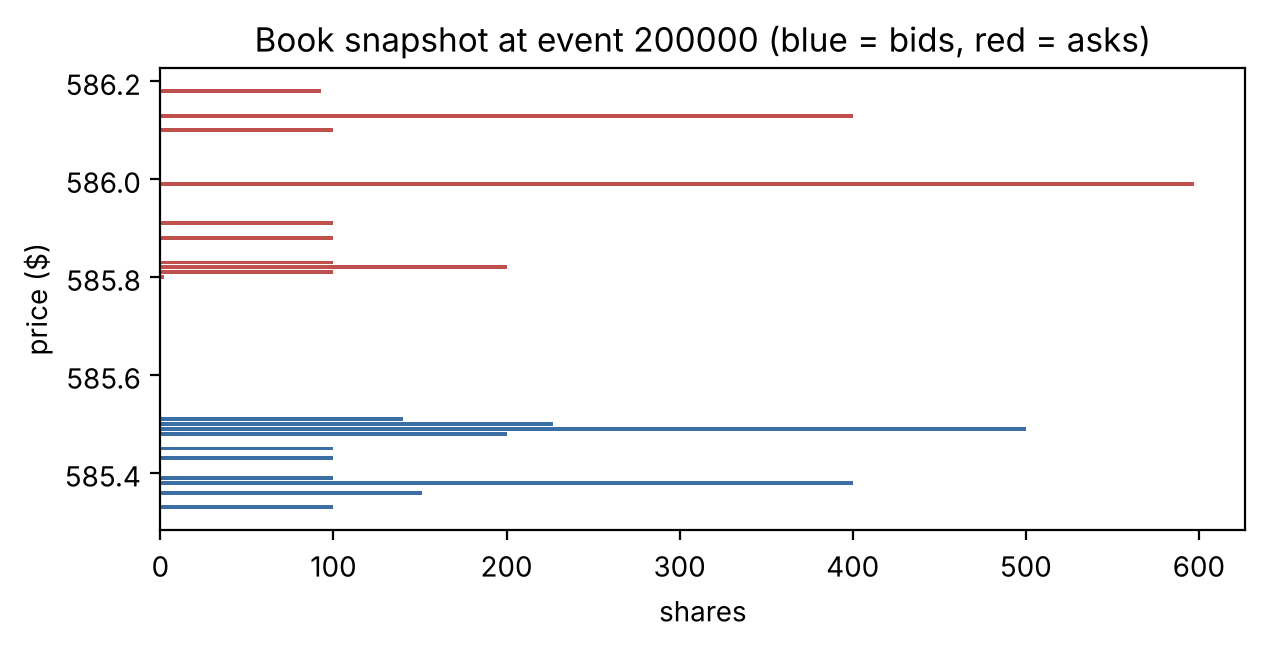

In [3]:
mid = ((df.ask_p1 + df.bid_p1) / 2).to_numpy()
spread = (df.ask_p1 - df.bid_p1).to_numpy()
print('spread ($): median %.3f, mean %.3f' % (np.median(spread), spread.mean()))
i = 200_000
row = df.iloc[i]
fig, ax = plt.subplots(figsize=(7,3))
for lv in range(1, 11):
    ax.barh(row[f'bid_p{lv}'], row[f'bid_s{lv}'], height=0.008, color='#3b6ea5')
    ax.barh(row[f'ask_p{lv}'], row[f'ask_s{lv}'], height=0.008, color='#c0504d')
ax.set(xlabel='shares', ylabel='price ($)', title=f'Book snapshot at event {i} (blue = bids, red = asks)');

## 2. Features
36 features in six groups. See `src/features.py` and the study guide for the definition of each one.

In [4]:
X = build_features(df)
print(X.shape)
X.describe().T[['mean','std','min','max']].round(4)

(400000, 36)


,mean,std,min,max
mid_price,587.0309,1.2933,583.3700,590.1900
best_bid,586.9329,1.2970,582.9600,590.1700
best_ask,587.1288,1.3000,583.3900,590.3000
microprice,587.0314,1.2946,583.3175,590.2025
book_vwap_5,587.0291,1.2969,583.4033,590.2383
spread,0.1959,0.2324,0.0100,2.6000
spread_bps,3.3370,3.9579,0.1695,44.2546
microprice_dev,-0.0005,0.2697,-0.4997,0.4996
wmid5_dev,-0.0043,2.2361,-57.5354,118.4791
ask_gap_12,0.0425,0.0616,0.0100,1.9600


## 3. Labels and the time split
Label = sign of (mean of the next k=50 mids minus the current mid), with a dead zone of ±alpha for 'flat'. Alpha comes from the training period only. The split is chronological, with k events purged at each boundary.

In [5]:
k = 50
tr, va, te = time_split(len(df), k)
fret = smoothed_future_return(pd.Series(mid), k)
alpha = choose_alpha(fret.iloc[tr])
y = make_labels(fret, alpha).fillna(1).astype(int).to_numpy()
print('alpha = %.2e (about %.2f cents at this price)' % (alpha, alpha * mid.mean() * 100))
for n, ix in (('train', tr), ('val', va), ('test', te)):
    print(n, len(ix), np.bincount(y[ix], minlength=3) / len(ix))

alpha = 2.46e-05 (about 1.44 cents at this price)
train 279950 [0.33175567 0.33333452 0.33490981]
val 59950 [0.31746455 0.3187156  0.36381985]
test 59950 [0.34155129 0.34066722 0.31778148]


## 4. LightGBM on all 36 features vs a random baseline

In [6]:
prior = np.bincount(y[tr], minlength=3) / len(tr)
rb, rb_sd = random_baseline_f1(y[te], prior)
mA = train_lgbm(X.iloc[tr], y[tr], X.iloc[va], y[va])
for n, ix in (('train', tr), ('val', va), ('test', te)):
    print(n, round(macro_f1(y[ix], mA.predict(X.iloc[ix])), 4))
print('random baseline (test):', round(rb, 4))

train 0.5756


val 0.4684


test 0.4737
random baseline (test): 0.3333


## 5. Diagnosing price-level leakage
Three checks: (1) how much gain the absolute-price features get, (2) whether their distribution shifts between train and test, (3) whether removing them hurts or helps out-of-sample.

In [7]:
gA = gain_importance(mA, X.columns)
print('gain share of absolute-price features: %.3f' % gA[ABSOLUTE_PRICE_FEATURES].sum())
print(gA[ABSOLUTE_PRICE_FEATURES].round(4))
adv = adversarial_auc(X.iloc[tr], X.iloc[te])
adv.head(8).round(3)

gain share of absolute-price features: 0.085
mid_price      0.0192
best_bid       0.0203
best_ask       0.0246
microprice     0.0120
book_vwap_5    0.0087
dtype: float64


book_vwap_5             0.808
microprice              0.807
mid_price               0.807
best_ask                0.806
best_bid                0.804
event_rate_100          0.778
log_time_since_trade    0.577
imb_l10                 0.545
dtype: float64

In [8]:
cols = [c for c in X.columns if c not in ABSOLUTE_PRICE_FEATURES]
mB = train_lgbm(X.iloc[tr][cols], y[tr], X.iloc[va][cols], y[va])
res = pd.DataFrame({
    'all 36': [macro_f1(y[ix], mA.predict(X.iloc[ix])) for ix in (tr, va, te)],
    'no abs price (31)': [macro_f1(y[ix], mB.predict(X.iloc[ix][cols])) for ix in (tr, va, te)],
}, index=['train', 'val', 'test']).round(4)
res

,all 36,no abs price (31)
train,0.5756,0.5545
val,0.4684,0.4714
test,0.4737,0.4791


## 6. Backtest
Threshold theta is chosen on the validation set, then applied once to the test set.

In [9]:
pte = mB.predict_proba(X.iloc[te][cols])
rows = [run_backtest(pte, mid, spread, te, k, th) for th in (0.0, 0.1, 0.2, 0.3, 0.4)]
pd.DataFrame(rows)[['theta','n_trades','hit_rate','mean_raw_pnl','mean_cost','sharpe_raw','sharpe_net']].round(4)

,theta,n_trades,hit_rate,mean_raw_pnl,mean_cost,sharpe_raw,sharpe_net
0,0.0,59950,0.5571,0.0245,0.2105,0.1590,-0.6835
1,0.1,29745,0.6103,0.0446,0.2068,0.2833,-0.6788
2,0.2,11738,0.6556,0.0641,0.2035,0.3777,-0.6579
3,0.3,3342,0.7391,0.0932,0.2156,0.4872,-0.6174
4,0.4,545,0.7927,0.1467,0.2498,0.5543,-0.5576


## 7. Saved results
The full numbers from `run_pipeline.py` are in `results/metrics.json`.

In [10]:
r = json.load(open('../results/metrics.json'))
print(json.dumps({k_: r[k_] for k_ in ('n_events','random_baseline_macro_f1')}, indent=1))
print(json.dumps(r['model_no_abs_price']['macro_f1'], indent=1))
print(json.dumps(r['backtest']['test'], indent=1))

{
 "n_events": 400000,
 "random_baseline_macro_f1": {
  "val": 0.33295741032143733,
  "test": 0.3333335877521023,
  "test_std": 0.0020352983437645017
 }
}
{
 "train": 0.5544743337219725,
 "val": 0.471441601005603,
 "test": 0.47905295053170205
}
{
 "theta": 0.4,
 "n_trades": 545,
 "hit_rate": 0.7926605504587156,
 "mean_raw_pnl": 0.14666055045871426,
 "mean_cost": 0.24976146788990577,
 "mean_net_pnl": -0.10310091743119151,
 "sharpe_raw": 0.5542518452144071,
 "sharpe_net": -0.5576309187803851,
 "total_raw_pnl": 79.92999999999927,
 "total_net_pnl": -56.18999999999937,
 "breakeven_cost": 0.14666055045871426
}
